# One-way ANOVA: the full workflow — Code-Along Template

**Type into this notebook during class.** The explanation is here; the code is not.

| | |
|---|---|
| **Follow along** | Write the code in each `# TODO` cell. The hint names the functions and arguments. |
| **If you fall behind** | Do not copy frantically. Skip to the next **CHECKPOINT**, run it, rejoin. |
| **If a cell errors** | Later cells depend on it and will fail too. Run the next CHECKPOINT rather than debugging under time pressure. |
| **After class** | The worked version is `D016_04_one_way_anova_KEY.ipynb`. Compare, do not copy. |

Cells that are already filled in are deliberate — imports and quick glances at the
data cost class time and teach nothing.

# One-Way ANOVA with `pingouin` — Instructor Notebook

## 1. Lesson Title
**One-Way ANOVA Using the `pingouin` Library**

> This notebook contains the complete worked solutions. Use it for delivery and to mark student submissions.

## 2. Learning Outcomes

By the end of this lesson, students should be able to:

1. Explain what a **One-Way ANOVA** is
2. Identify the **independent variable** and **dependent variable**
3. Load and inspect a suitable dataset
4. Check important assumptions before running ANOVA
5. Run a **One-Way ANOVA** using `pingouin`
6. Interpret the ANOVA table
7. Perform **post hoc tests** after ANOVA
8. Write a short conclusion based on the results

## 3. Business / Real-World Scenario

A lecturer wants to investigate whether students from different **study habit groups** have different **exam scores**.

- **Independent Variable:** `Study_Habit` (Poor, Average, Excellent)
- **Dependent Variable:** `Exam_Score`

Suitable for **One-Way ANOVA** because: one categorical IV with 3+ groups and one continuous DV.

## 4. What is One-Way ANOVA?

Tests whether the means of **three or more independent groups** are significantly different.

*Do students with different study habits get different average exam scores?*

## 5. When do we use One-Way ANOVA?

1. one categorical IV
2. 3 or more groups
3. one continuous DV
4. groups are independent

## 6. Install Required Libraries

In [1]:
# !pip install pingouin pandas numpy scipy seaborn matplotlib statsmodels

In [ ]:
# ═══ CHECKPOINT — "Import Libraries" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

pass

print("Checkpoint restored. Ready for: Import Libraries")

## 7. Import Libraries

In [2]:
import numpy as np
import pandas as pd
import pingouin as pg
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

## 8. Load the Dataset

Data is already prepared in `../data/study_habit.csv`.

In [ ]:
# TODO: compute `df` from `Study_Habit`
# Hint: pd.read_csv, .astype(), df.head
# Name your result: df

## 9. Understand the Dataset

In [4]:
print('Shape:', df.shape)
print('\nFirst 5 rows:')
print(df.head())
print('\nGroup counts:')
print(df['Study_Habit'].value_counts())
print('\nData types:')
print(df.dtypes)

Shape: (75, 2)

First 5 rows:
  Study_Habit  Exam_Score
0        Poor       56.83
1        Poor       48.76
2        Poor       59.50
3        Poor       60.64
4        Poor       43.29

Group counts:
Study_Habit
Average      25
Excellent    25
Poor         25
Name: count, dtype: int64

Data types:
Study_Habit    category
Exam_Score      float64
dtype: object


## 10. Descriptive Statistics

In [5]:
df.groupby('Study_Habit', observed=True)['Exam_Score'].agg(['mean', 'std', 'count'])

,mean,std,count
Study_Habit,,,
Average,69.3068,4.160387,25
Excellent,81.2228,4.974268,25
Poor,54.7876,4.987265,25


In [ ]:
# ═══ CHECKPOINT — "Visualize the Data" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
import pandas as pd
import pingouin as pg
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('../../00-data/study_habit.csv', index_col=0)
df['Study_Habit'] = df['Study_Habit'].astype('category')

print("Checkpoint restored. Ready for: Visualize the Data")

## 11. Visualize the Data

### 11.1 Boxplot

In [ ]:
# TODO: draw a boxplot of `Study_Habit`
# Hint: plt.figure, sns.boxplot, plt.title, plt.show

### 11.2 Stripplot

In [ ]:
# TODO: draw a `plt.figure` of `Study_Habit`
# Hint: plt.figure, sns.stripplot, plt.title, plt.show

## 12. Assumptions Before Running One-Way ANOVA

1. dependent variable is continuous
2. independent variable is categorical
3. groups are independent
4. no extreme outliers
5. normality within each group
6. homogeneity of variance

## 13. Check for Potential Outliers

`|z| > 3` may suggest unusual observations. Investigate, do not auto-remove.

In [ ]:
# TODO: compute `outliers` from `z_score`, `Exam_Score`
# Hint: stats.zscore, np.abs
# Name your result: outliers

## 14. Check Normality Within Each Group

Shapiro-Wilk via `pg.normality()`.
- H0: data is normally distributed
- p > 0.05 → normality not violated

In [ ]:
# TODO: compute `normality_summary`, `subset`, `result` from `Study_Habit`, `Exam_Score`, `W`
# Hint: pd.DataFrame, pg.normality, normality_summary.append
# Name your result: normality_summary, subset, result, normality_df

In [ ]:
# ═══ CHECKPOINT — "Q-Q Plot for Visual Normality Check" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
import pandas as pd
import pingouin as pg
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('../../00-data/study_habit.csv', index_col=0)
df['Study_Habit'] = df['Study_Habit'].astype('category')
df['z_score'] = stats.zscore(df['Exam_Score'])
outliers = df[np.abs(df['z_score']) > 3]
normality_summary = []
for habit in df['Study_Habit'].cat.categories:
    subset = df[df['Study_Habit'] == habit]['Exam_Score']
    result = pg.normality(subset)
    normality_summary.append({'Study_Habit': habit, 'W': result['W'].values[0], 'p-value': result['pval'].values[0], 'Normal?': result['normal'].values[0]})
normality_df = pd.DataFrame(normality_summary)

print("Checkpoint restored. Ready for: Q-Q Plot for Visual Normality Check")

## 15. Q-Q Plot for Visual Normality Check

In [ ]:
# TODO: draw a `plt.figure` of `Study_Habit`
# Hint: plt.figure, stats.probplot, plt.title, plt.show
# Name your result: subset

## 16. Check Homogeneity of Variance (Homoscedasticity)

Levene's test via `pg.homoscedasticity()`.
- H0: variances are equal
- p > 0.05 → homogeneity assumption satisfied

In [ ]:
# TODO: compute `levene_result`, `data`, `dv`
# Hint: pg.homoscedasticity
# Name your result: levene_result, data, dv, group

## 17. Run One-Way ANOVA

In [ ]:
# TODO: run an ANOVA on `Exam_Score` across `Study_Habit`, storing the result in `anova_results`
# Hint: pg.anova
# Name your result: anova_results, data, dv, between

## 18. How to Read the ANOVA Output

- `Source` → factor being tested
- `SS` → sum of squares
- `DF` → degrees of freedom
- `MS` → mean square
- `F` → F-statistic
- `p_unc` → p-value
- `np2` → partial eta squared (effect size)

**H0:** all group means are equal &nbsp;|&nbsp; **H1:** at least one differs

- `p < 0.05` → at least one group mean is significantly different
- `p > 0.05` → no evidence of a significant difference

## 19. Why Do We Need Post Hoc Tests?

ANOVA tells us **at least one group differs**, but not **which** ones.

## 20. Post Hoc Test Using Tukey

Compare every pair of groups with adjusted p-values.

In [13]:
posthoc_results = pg.pairwise_tukey(
    data=df,
    dv='Exam_Score',
    between='Study_Habit'
)
posthoc_results

,A,B,mean_A,mean_B,diff,se,T,p_tukey,hedges
0,Average,Excellent,69.3068,81.2228,-11.9160,1.335914,-8.919737,8.770762e-13,-2.557854
1,Average,Poor,69.3068,54.7876,14.5192,1.335914,10.868365,0.000000e+00,3.111863
2,Excellent,Poor,81.2228,54.7876,26.4352,1.335914,19.788102,0.000000e+00,5.224089


In [ ]:
# ═══ CHECKPOINT — "Optional Group Means Table" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
import pandas as pd
import pingouin as pg
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('../../00-data/study_habit.csv', index_col=0)
df['Study_Habit'] = df['Study_Habit'].astype('category')
df['z_score'] = stats.zscore(df['Exam_Score'])
outliers = df[np.abs(df['z_score']) > 3]
normality_summary = []
for habit in df['Study_Habit'].cat.categories:
    subset = df[df['Study_Habit'] == habit]['Exam_Score']
    result = pg.normality(subset)
    normality_summary.append({'Study_Habit': habit, 'W': result['W'].values[0], 'p-value': result['pval'].values[0], 'Normal?': result['normal'].values[0]})
normality_df = pd.DataFrame(normality_summary)
for habit in df['Study_Habit'].cat.categories:
    subset = df[df['Study_Habit'] == habit]['Exam_Score']
    plt.figure(figsize=(5, 4))
    stats.probplot(subset, dist='norm', plot=plt)
    plt.title(f'Q-Q Plot: {habit}')
    plt.show()
levene_result = pg.homoscedasticity(data=df, dv='Exam_Score', group='Study_Habit', method='levene')
anova_results = pg.anova(data=df, dv='Exam_Score', between='Study_Habit', detailed=True)
posthoc_results = pg.pairwise_tukey(data=df, dv='Exam_Score', between='Study_Habit')

print("Checkpoint restored. Ready for: Optional Group Means Table")

## 21. Optional Group Means Table

In [14]:
mean_table = df.groupby('Study_Habit', observed=True)['Exam_Score'].mean().reset_index()
mean_table

,Study_Habit,Exam_Score
0,Average,69.3068
1,Excellent,81.2228
2,Poor,54.7876


## 22. Interpretation Template (Worked Example)

> A one-way ANOVA was conducted to test whether mean exam scores differ across the three study habit groups (Poor, Average, Excellent).
>
> The ANOVA result showed a **statistically significant** difference in exam scores among the study habit groups (`F`, `p-unc < .001`, `np2 ≈ 0.7`), indicating a large effect of study habit on exam performance.
>
> Tukey post hoc comparisons showed that **all three pairwise comparisons** (Poor vs Average, Poor vs Excellent, Average vs Excellent) were significantly different (`p-tukey < .05`). Students with Excellent study habits scored highest on average, followed by Average, then Poor.

## 23. Student Exercise — Suggested Solution Outline

Apply the same workflow to a 3-level categorical IV (e.g. `Diet_Type`) and a continuous DV (e.g. `Energy_Level`).

Below is a reference template instructors can demonstrate live.

In [15]:
# Reference template — replace with the student's chosen dataset
# ex_df = pd.read_csv('your_exercise_data.csv')
# ex_df['Diet_Type'] = ex_df['Diet_Type'].astype('category')
#
# print(ex_df.groupby('Diet_Type', observed=True)['Energy_Level'].agg(['mean', 'std', 'count']))
#
# sns.boxplot(data=ex_df, x='Diet_Type', y='Energy_Level'); plt.show()
#
# # Outliers
# ex_df['z'] = stats.zscore(ex_df['Energy_Level'])
# print(ex_df[np.abs(ex_df['z']) > 3])
#
# # Normality per group
# for g in ex_df['Diet_Type'].cat.categories:
#     print(g, pg.normality(ex_df[ex_df['Diet_Type'] == g]['Energy_Level']))
#
# # Homogeneity of variance
# print(pg.homoscedasticity(data=ex_df, dv='Energy_Level', group='Diet_Type', method='levene'))
#
# # ANOVA
# print(pg.anova(data=ex_df, dv='Energy_Level', between='Diet_Type', detailed=True))
#
# # Tukey post hoc
# print(pg.pairwise_tukey(data=ex_df, dv='Energy_Level', between='Diet_Type'))

## 24. Reflection Questions — Model Answers

**1. What does the null hypothesis in One-Way ANOVA mean?**
> The null hypothesis states that all group population means are equal. Any observed differences in sample means are attributable to random sampling variation.

**2. Why can we not stop at the ANOVA result when it is significant?**
> Because ANOVA only tells us that *at least one* group mean differs from the others — it does not identify which specific groups differ.

**3. What does Tukey post hoc tell us?**
> It performs all pairwise group comparisons while controlling the family-wise Type I error rate, identifying exactly which pairs of groups have significantly different means.

**4. Why do we check homogeneity of variance?**
> Standard ANOVA assumes equal variances across groups. Violating this can inflate Type I error, particularly with unbalanced sample sizes. If violated, use Welch's ANOVA (`pg.welch_anova`) or Games-Howell post hoc.

**5. Why is One-Way ANOVA preferred over multiple t-tests when comparing 3 or more groups?**
> Running many pairwise t-tests inflates the family-wise Type I error rate. ANOVA conducts a single omnibus test that controls this error rate at the chosen alpha (e.g. 0.05).

## 25. Quick Summary Rule Chart

**Before ANOVA — check:** numeric DV, categorical IV, independent groups, no extreme outliers, normality within groups, homogeneity of variance.

**After ANOVA:**
- `p > 0.05` → no significant mean difference
- `p < 0.05` → at least one group mean differs → run **Tukey post hoc**

## 26. Summary

Students learned to: load and inspect data, visualize, check assumptions (normality, homoscedasticity), run One-Way ANOVA via `pingouin`, perform Tukey post hoc, and write a clear conclusion.

## Appendix — Full End-to-End Workflow Cell

Useful for live demonstration.

Descriptive statistics:
                mean       std  count
Study_Habit                          
Average      69.3068  4.160387     25
Excellent    81.2228  4.974268     25
Poor         54.7876  4.987265     25


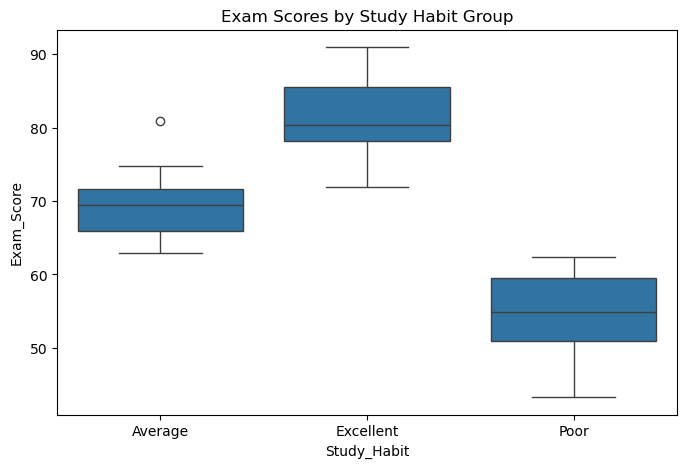


Potential outliers:
Empty DataFrame
Columns: [Study_Habit, Exam_Score, z_score]
Index: []

Normality:
  Study_Habit         W   p-value  Normal?
0     Average  0.942420  0.168335     True
1   Excellent  0.978505  0.853952     True
2        Poor  0.966795  0.565361     True

Levene:
               W      pval  equal_var
levene  0.855401  0.429387       True

ANOVA:
        Source           SS  DF           MS           F         p_unc  \
0  Study_Habit  8763.483531   2  4381.741765  196.417348  6.937813e-30   
1       Within  1606.199304  72    22.308324         NaN           NaN   

        np2  
0  0.845106  
1       NaN  

Tukey post hoc:
           A          B   mean_A   mean_B     diff        se          T  \
0    Average  Excellent  69.3068  81.2228 -11.9160  1.335914  -8.919737   
1    Average       Poor  69.3068  54.7876  14.5192  1.335914  10.868365   
2  Excellent       Poor  81.2228  54.7876  26.4352  1.335914  19.788102   

        p_tukey    hedges  
0  8.770762e-13 -2.55

In [16]:
import numpy as np
import pandas as pd
import pingouin as pg
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load data
df = pd.read_csv('../../00-data/study_habit.csv', index_col=0)
df['Study_Habit'] = df['Study_Habit'].astype('category')

print('Descriptive statistics:')
print(df.groupby('Study_Habit', observed=True)['Exam_Score'].agg(['mean', 'std', 'count']))

# 2. Visualizations
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Study_Habit', y='Exam_Score')
plt.title('Exam Scores by Study Habit Group')
plt.show()

# 3. Outlier check
df['z_score'] = stats.zscore(df['Exam_Score'])
print('\nPotential outliers:')
print(df[np.abs(df['z_score']) > 3])

# 4. Normality per group
rows = []
for habit in df['Study_Habit'].cat.categories:
    subset = df[df['Study_Habit'] == habit]['Exam_Score']
    r = pg.normality(subset)
    rows.append({'Study_Habit': habit, 'W': r['W'].values[0],
                 'p-value': r['pval'].values[0], 'Normal?': r['normal'].values[0]})
print('\nNormality:')
print(pd.DataFrame(rows))

# 5. Homogeneity of variance
print('\nLevene:')
print(pg.homoscedasticity(data=df, dv='Exam_Score', group='Study_Habit', method='levene'))

# 6. ANOVA
print('\nANOVA:')
print(pg.anova(data=df, dv='Exam_Score', between='Study_Habit', detailed=True))

# 7. Tukey post hoc
print('\nTukey post hoc:')
print(pg.pairwise_tukey(data=df, dv='Exam_Score', between='Study_Habit'))